In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_selector,make_column_transformer
import numpy as np
from tqdm import tqdm
from sklearn.metrics import r2_score

In [2]:
df=pd.read_csv("F:\MACHINE LEARNING\SOMETHING\Datasets\Housing.csv")
X,y=df.drop('price',axis=1),df['price']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.3,random_state=26)

In [7]:
ohe=OneHotEncoder(sparse_output=False,drop='first').set_output(transform='pandas')
ct=make_column_transformer((ohe,make_column_selector(dtype_include=object)),
                           ('passthrough',make_column_selector(dtype_exclude=object)), verbose_feature_names_out=False ).set_output(transform='pandas')
ct=ct.set_output(transform='pandas')
ct_ohe_tr=ct.fit_transform(X_train)
ct_ohe_tst=ct.transform(X_test)


In [12]:
depths=[None,1,2,3,4,5,6,7]
min_leaf=[1,0.05,0.01,0.2,.3]
min_split=[2,0.05,0.01,0.2,0.3]
scores=[]
for d in depths:
    for l in min_leaf:
        for s in min_split:
            dt=DecisionTreeRegressor(random_state=26,max_depth=d,min_samples_leaf=l,min_samples_split=s)
            dt.fit(ct_ohe_tr,y_train)
            pred=dt.predict(ct_ohe_tst)
            scores.append([d,s,l,r2_score(y_test,pred)])
score_df=pd.DataFrame(scores,columns=["depths",'min_split','min_leaf','r2_score' ])
score_df.sort_values(by="r2_score",ascending=False,ignore_index=True)[:20]

,depths,min_split,min_leaf,r2_score
0,NaN,0.05,0.05,0.526436
1,NaN,0.01,0.05,0.526436
2,NaN,2.00,0.05,0.526436
3,7.0,0.01,0.05,0.526436
4,7.0,2.00,0.05,0.526436
5,5.0,0.01,0.05,0.526436
6,5.0,2.00,0.05,0.526436
7,5.0,0.05,0.05,0.526436
8,6.0,0.05,0.05,0.526436
9,6.0,0.01,0.05,0.526436


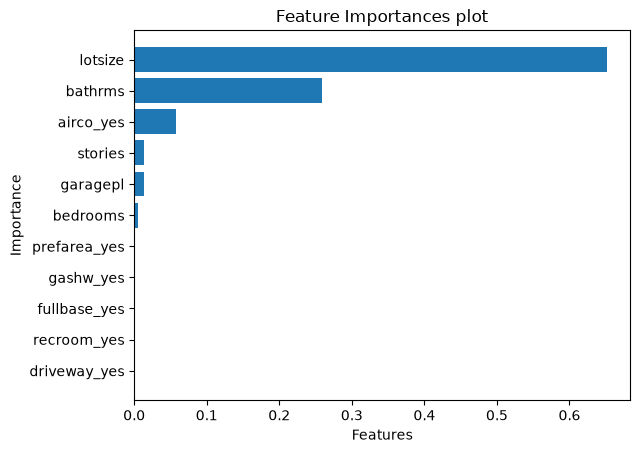

In [13]:
best_tree = DecisionTreeRegressor(random_state=26,max_depth=None, min_samples_split= 0.05, min_samples_leaf= 0.05)

best_tree.fit(ct.transform(X), y)
df_imp = pd.DataFrame({'features': list(ct.transform(X).columns),
                       'importance': best_tree.feature_importances_})
df_imp.sort_values('importance', inplace = True)
plt.barh(df_imp['features'], df_imp['importance'])
plt.title("Feature Importances plot")
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()